# 01b - Network cleaning, window-level dataset and augmentation
**Project:** multimodal intrusion detection in 5G Open RAN (NetsLab-5GORAN-IDD, Version 1).
**Input:** the per-scenario *packet* CSVs (`filtered*.csv`). **Outputs:** `network_clean.csv`, `network_features.csv` (+ a feature-list json).

**Design decisions (all are knobs in the next cell)**

| Decision | Choice | Why |
|---|---|---|
| Unit of analysis | 1-second windows, aligned to whole UTC seconds | matches the 1 Hz radio telemetry; flows collapse floods into 2-12 rows and have no timestamp |
| Duplicates | exact duplicate packet rows removed (per capture) | proposal section 8.1; up to 20% of rows in some captures |
| Partial edge windows | dropped, except in captures too short to have 10 full windows (the PortScan runs) | a half-covered second under-counts packets |
| Leakage | no IPs, ports (identity), time, `tcp.stream`, TTL or TCP window in the model features | they identify the capture or the attack tool; TTL/window are kept as `diag_` columns in the clean file only |
| Augmentation | **phase-shifted re-windowing** of the real packets (0.25 / 0.5 / 0.75 s offsets) for Benign and PortScan | every row is a real, physically valid window; no invented feature values |
| Shuffle | `network_features.csv` is shuffled; `network_clean.csv` stays in time order | drift / replay attacks and radio alignment need time order; the time columns are in both files |

**Important limits of the augmentation** (also repeated at the end): augmented windows overlap their parent window by 75 %, so they are *correlated*, not independent samples; they must only be used in **training** folds, grouped by `scenario`; and they start off the whole-second grid, so they have **no radio partner** (use them for the network-only model, not for paired multimodal rows).

## 1. Configuration and dataset discovery

In [1]:
import os, re, json, time, pickle, hashlib, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 80, "display.width", 250, "display.max_rows", 120, "display.float_format", "{:,.3f}".format)

# ------------------------------- knobs -------------------------------
CHUNK              = 400_000     # rows per read chunk
MAX_ROWS_PER_FILE  = None        # e.g. 200_000 for a quick test run; None = every packet
RANDOM_STATE       = 42
TZ_OFFSETS         = {"GMT": 0, "UTC": 0, "IST": 3600}   # seconds the label adds to UTC. IST=+1h is what the earlier radio/packet overlap
                                                         # check supported (real IST would be +19800) - verify in the alignment notebook.
FIELD_PICK         = "last"      # tunnelled packets hold "outer,inner" values: "last" = inner (UE-side) header, "first" = outer (GTP) header
DEDUP              = True        # drop exact duplicate packet rows inside each capture
SUBN               = 4           # sub-bins per second (0.25 s). A window = SUBN sub-bins = 1 s; phase step = 1/SUBN s
MIN_FULL_WINDOWS   = 10          # captures with fewer full windows than this keep their partial windows (flagged is_partial=1)
AUG_FAMILIES       = ["Benign", "PortScan"]   # families that get phase-shifted windows
BENIGN_TO_ATTACK   = 1.0         # add augmented Benign windows until Benign ~= this x (real attack windows); 0 = no benign augmentation
FAMILY_FLOOR       = 150         # other augmented families are topped up towards this many windows (limited by what the captures allow)
SHUFFLE_CLEAN      = False       # network_clean.csv stays time-ordered by default
RUN_SANITY         = True        # small scenario-held-out check: real-only vs real+augmented training
USE_CACHE          = True        # per-scenario window cache (delete OUT/_cache to force a rescan)
REQUIRE_ALL        = os.environ.get("REQUIRE_ALL", "1") == "1"

def find_base():
    cands = [os.environ.get("NETSLAB_BASE"), "/kaggle/input/datasets/netslabdemo/netslab-5g-oran-idd", "/kaggle/input/netslab-5g-oran-idd"]
    for c in cands:
        if c and os.path.isdir(c): return c
    root0 = "/kaggle/input"
    for root, dirs, _ in os.walk(root0):
        if root.count(os.sep) - root0.count(os.sep) > 4: dirs[:] = []; continue
        if "Attack (Legacy) Version 1" in dirs: return root
    return None

BASE = find_base()
if BASE is None:
    raise FileNotFoundError("Dataset not found under /kaggle/input. Add 'netslabdemo/netslab-5g-oran-idd' as an input (right sidebar > Add Input), then Restart & Run All.")
V1  = os.path.join(BASE, "Attack (Legacy) Version 1")
OUT = "/kaggle/working" if os.path.isdir("/kaggle/working") else os.environ.get("OUT_DIR", "./outputs")
os.makedirs(OUT, exist_ok=True)
INDEX = {}
for root, _, files in os.walk(V1):
    for f in files: INDEX.setdefault(f, os.path.join(root, f))
print("BASE:", BASE); print("V1 files indexed:", len(INDEX)); print("OUT :", OUT)

BASE: /kaggle/input/datasets/netslabdemo/netslab-5g-oran-idd
V1 files indexed: 220
OUT : /kaggle/working


## 2. Scenario manifest
Scenario, family, mode and the binary label come from the file name, the same way as in notebook 01.

In [2]:
STEMS = (["filteredBenign%d" % i for i in range(1, 7)] +
         ["filtered%s%d" % (p, i) for p in ["TCP", "DDOSTCP", "SYN", "DDOSSYN"] for i in range(1, 4)] +
         ["filteredUDP%d" % i for i in range(1, 6)] + ["filteredDDOSUDP%d" % i for i in range(1, 4)] +
         ["filtered%s%d" % (p, i) for p in ["ICMP", "DDOSICMP", "PortScan"] for i in range(1, 4)])

def describe(stem):
    sc = stem.replace("filtered", "", 1); low = sc.lower()
    if   "benign"   in low: fam, mode = "Benign", "Benign"
    elif "portscan" in low: fam, mode = "PortScan", "PortScan"
    else:
        fam  = "SYN" if "syn" in low else "TCP" if "tcp" in low else "UDP" if "udp" in low else "ICMP" if "icmp" in low else "Unknown"
        mode = "DDoS" if low.startswith("ddos") else "DoS"
    class_fm = fam if fam in ("Benign", "PortScan") else f"{fam}_{mode}"
    return dict(stem=stem, scenario=sc, family=fam, mode=mode, class_fm=class_fm, is_attack=int(fam != "Benign"))

MAN = pd.DataFrame([dict(describe(s), pkt_path=INDEX.get(s + ".csv")) for s in STEMS])
missing = MAN[MAN.pkt_path.isna()].scenario.tolist()
print(f"packet CSVs found: {MAN.pkt_path.notna().sum()}/{len(MAN)}")
if missing:
    msg = f"missing packet CSVs: {missing}"
    if REQUIRE_ALL: raise FileNotFoundError(msg + "  (set REQUIRE_ALL=0 to continue with the files that exist)")
    print("WARNING -", msg)
MAN = MAN[MAN.pkt_path.notna()].reset_index(drop=True)
display(MAN[["scenario", "family", "mode", "class_fm", "is_attack"]].T)

packet CSVs found: 35/35


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34
scenario,Benign1,Benign2,Benign3,Benign4,Benign5,Benign6,TCP1,TCP2,TCP3,DDOSTCP1,DDOSTCP2,DDOSTCP3,SYN1,SYN2,SYN3,DDOSSYN1,DDOSSYN2,DDOSSYN3,UDP1,UDP2,UDP3,UDP4,UDP5,DDOSUDP1,DDOSUDP2,DDOSUDP3,ICMP1,ICMP2,ICMP3,DDOSICMP1,DDOSICMP2,DDOSICMP3,PortScan1,PortScan2,PortScan3
family,Benign,Benign,Benign,Benign,Benign,Benign,TCP,TCP,TCP,TCP,TCP,TCP,SYN,SYN,SYN,SYN,SYN,SYN,UDP,UDP,UDP,UDP,UDP,UDP,UDP,UDP,ICMP,ICMP,ICMP,ICMP,ICMP,ICMP,PortScan,PortScan,PortScan
mode,Benign,Benign,Benign,Benign,Benign,Benign,DoS,DoS,DoS,DDoS,DDoS,DDoS,DoS,DoS,DoS,DDoS,DDoS,DDoS,DoS,DoS,DoS,DoS,DoS,DDoS,DDoS,DDoS,DoS,DoS,DoS,DDoS,DDoS,DDoS,PortScan,PortScan,PortScan
class_fm,Benign,Benign,Benign,Benign,Benign,Benign,TCP_DoS,TCP_DoS,TCP_DoS,TCP_DDoS,TCP_DDoS,TCP_DDoS,SYN_DoS,SYN_DoS,SYN_DoS,SYN_DDoS,SYN_DDoS,SYN_DDoS,UDP_DoS,UDP_DoS,UDP_DoS,UDP_DoS,UDP_DoS,UDP_DDoS,UDP_DDoS,UDP_DDoS,ICMP_DoS,ICMP_DoS,ICMP_DoS,ICMP_DDoS,ICMP_DDoS,ICMP_DDoS,PortScan,PortScan,PortScan
is_attack,0,0,0,0,0,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1


## 3. Packet reader (one streaming pass per capture)
Each capture is read once in chunks. Per chunk: exact duplicates are dropped, `frame.time` is parsed with its time-zone label, and the packets are summarised into **0.25 s sub-bins** (additive counts, plus per-(sub-bin, value) counts for source IP, destination IP, source port and destination port).
Sub-bins can be added up to any window start, so one pass gives both the aligned 1-s windows and the phase-shifted ones, even though packet timestamps are not monotonic inside a capture.

Protocol is taken from `frame.protocols` (innermost of tcp / udp / icmp), because `ip.proto` of a GTP-encapsulated packet starts with the outer UDP value.

In [3]:
PKT_COLS = ["frame.time","frame.len","frame.protocols","ip.src","ip.dst","ip.proto","ip.ttl","ip.len","ip.id","ip.flags",
            "tcp.srcport","tcp.dstport","tcp.flags","tcp.seq","tcp.ack","tcp.len","tcp.window_size_value","tcp.stream",
            "udp.srcport","udp.dstport","udp.length","icmp.type","icmp.code"]
_RX = re.compile(r"^\s*([A-Za-z]{3})\s+(\d{1,2}),\s+(\d{4})\s+(\d{2}):(\d{2}):(\d{2})(?:\.(\d{1,9}))?\s*([A-Za-z]+)?")

def pick(s, how=None):
    how = how or FIELD_PICK
    s = s.astype("string")
    t = s.str.split(",", n=1).str[0] if how == "first" else s.str.rsplit(",", n=1).str[-1]
    return t.str.strip()
def to_num(s): return pd.to_numeric(pick(s), errors="coerce").astype("float64")
def hex_num(s):
    f = pick(s); u = pd.Series(f.dropna().unique(), dtype="object")
    m = {v: int(v, 16) for v in u if isinstance(v, str) and re.fullmatch(r"0x[0-9a-fA-F]+", v)}
    return f.map(m).astype("float64")
def hash_vals(s):
    return pd.util.hash_pandas_object(pick(s).fillna("").astype(object), index=False).values.view("int64")

def parse_time(s):
    """'Mar  6, 2025 14:37:50.545026086 GMT' -> (epoch seconds in UTC as float, tz label). Vectorised; keeps the tz label."""
    x = s.astype("string").str.extract(_RX)
    stamp = x[2] + " " + x[0] + " " + x[1].str.zfill(2) + " " + x[3] + ":" + x[4] + ":" + x[5]
    base = pd.to_datetime(stamp, format="%Y %b %d %H:%M:%S", errors="coerce")
    sec  = (base - pd.Timestamp("1970-01-01")).dt.total_seconds().astype("float64")
    frac = pd.to_numeric("0." + x[6].fillna("0"), errors="coerce").astype("float64")
    tz   = x[7].str.upper()
    off  = tz.map(TZ_OFFSETS).astype("float64")
    return (sec + frac - off.fillna(0)).astype("float64"), tz

def proto_info(u):
    toks = str(u).lower().split(":"); inner = "other"
    for t in toks:
        if t in ("tcp", "udp", "icmp"): inner = t          # the last one wins = innermost
    return inner, int("gtp" in toks)

BOOL_COLS = ["n_tcp","n_udp","n_icmp","n_gtp","n_syn","n_synack","n_rst","n_fin","n_ackonly"]

def scan_scenario(path):
    t0 = time.time()
    hdr  = pd.read_csv(path, nrows=0).columns
    cols = [c for c in PKT_COLS if c in hdr]
    parts, vcs = [], {k: [] for k in ("src", "dst", "sport", "dport")}
    seen = np.empty(0, dtype=np.uint64)
    n_read = n_dup = n_bad = 0; tmin, tmax = np.inf, -np.inf; tzc = {}
    for ch in pd.read_csv(path, dtype=str, usecols=cols, chunksize=CHUNK, low_memory=False):
        if MAX_ROWS_PER_FILE and n_read >= MAX_ROWS_PER_FILE: break
        if MAX_ROWS_PER_FILE: ch = ch.iloc[: MAX_ROWS_PER_FILE - n_read]
        for c in PKT_COLS:
            if c not in ch.columns: ch[c] = np.nan
        n_read += len(ch)
        if DEDUP:
            h   = pd.util.hash_pandas_object(ch[cols], index=False).values
            dup = pd.Series(h).duplicated().values | np.isin(h, seen)
            n_dup += int(dup.sum()); seen = np.concatenate([seen, h[~dup]])
            ch = ch[~dup]
        ch = ch.reset_index(drop=True)
        if not len(ch): continue
        ep, tz = parse_time(ch["frame.time"])
        ok = ep.notna().values
        n_bad += int((~ok).sum())
        if not ok.all():
            ch = ch[ok].reset_index(drop=True); ep = ep[ok].reset_index(drop=True); tz = tz[ok].reset_index(drop=True)
        if not len(ch): continue
        for k, v in tz.value_counts(dropna=True).items(): tzc[k] = tzc.get(k, 0) + int(v)
        epv = ep.values; tmin = min(tmin, float(epv.min())); tmax = max(tmax, float(epv.max()))
        sub = np.floor(epv * SUBN).astype("int64")

        L  = to_num(ch["frame.len"]).values
        pr = ch["frame.protocols"].astype(str); uq = pr.unique()
        inner = pr.map({u: proto_info(u)[0] for u in uq}).values
        gtp   = pr.map({u: proto_info(u)[1] for u in uq}).values.astype("int64")
        fl  = hex_num(ch["tcp.flags"]).fillna(-1).values.astype("int64"); has = fl >= 0
        d = pd.DataFrame({
            "sub": sub, "pkts": 1, "bytes": L, "len_sq": L * L, "len_min": L, "len_max": L,
            "n_tcp": inner == "tcp", "n_udp": inner == "udp", "n_icmp": inner == "icmp", "n_gtp": gtp,
            "n_syn": has & (fl == 0x02), "n_synack": has & (fl == 0x12), "n_rst": has & ((fl & 4) > 0),
            "n_fin": has & ((fl & 1) > 0), "n_ackonly": has & (fl == 0x10),
            "tcp_len": to_num(ch["tcp.len"]).values, "udp_len": to_num(ch["udp.length"]).values,
            "ttl": to_num(ch["ip.ttl"]).values, "win": to_num(ch["tcp.window_size_value"]).values})
        for c in BOOL_COLS: d[c] = d[c].astype("int64")
        parts.append(d.groupby("sub").agg(
            pkts=("pkts", "sum"), bytes=("bytes", "sum"), len_sq=("len_sq", "sum"), len_min=("len_min", "min"), len_max=("len_max", "max"),
            n_tcp=("n_tcp", "sum"), n_udp=("n_udp", "sum"), n_icmp=("n_icmp", "sum"), n_gtp=("n_gtp", "sum"),
            n_syn=("n_syn", "sum"), n_synack=("n_synack", "sum"), n_rst=("n_rst", "sum"), n_fin=("n_fin", "sum"), n_ackonly=("n_ackonly", "sum"),
            tcp_len_sum=("tcp_len", "sum"), udp_len_sum=("udp_len", "sum"),
            ttl_sum=("ttl", "sum"), ttl_cnt=("ttl", "count"), win_sum=("win", "sum"), win_cnt=("win", "count")))

        sp = to_num(ch["tcp.srcport"]).fillna(to_num(ch["udp.srcport"])).values
        dp = to_num(ch["tcp.dstport"]).fillna(to_num(ch["udp.dstport"])).values
        for name, vals, valid in [("src", hash_vals(ch["ip.src"]), None), ("dst", hash_vals(ch["ip.dst"]), None),
                                  ("sport", np.where(np.isnan(sp), -1, sp).astype("int64"), ~np.isnan(sp)),
                                  ("dport", np.where(np.isnan(dp), -1, dp).astype("int64"), ~np.isnan(dp))]:
            t = pd.DataFrame({"sub": sub, "v": vals})
            if valid is not None: t = t[valid]
            vcs[name].append(t.groupby(["sub", "v"]).size().rename("c").reset_index())

    if not parts: raise ValueError(f"no usable packets in {path}")
    B = pd.concat(parts).groupby(level=0).agg({**{c: "sum" for c in parts[0].columns}, "len_min": "min", "len_max": "max"}).sort_index()
    VC = {k: pd.concat(v, ignore_index=True).groupby(["sub", "v"], sort=False)["c"].sum().reset_index() if v else None for k, v in vcs.items()}
    tz_label = max(tzc, key=tzc.get) if tzc else "UNK"
    meta = dict(rows_read=n_read, dup_removed=n_dup, bad_time=n_bad, rows_kept=n_read - n_dup - n_bad, tmin=tmin, tmax=tmax,
                tz_label=tz_label, tz_labels_seen=",".join(f"{k}:{v}" for k, v in tzc.items()),
                tz_offset_assumed_s=TZ_OFFSETS.get(tz_label, 0), tz_unknown=int(tz_label not in TZ_OFFSETS), scan_s=round(time.time() - t0, 1))
    return dict(base=B, vcs=VC, meta=meta)

## 4. Window builder
For a window starting at sub-bin `k` the statistics of sub-bins `k .. k+3` are combined (counts add up; min/max are re-taken; distinct counts and entropies come from the merged value counts).
`phases=[0]` gives the whole-second windows (the *real* dataset); `phases=[0,1,2,3]` also gives the windows shifted by 0.25 / 0.5 / 0.75 s (the augmentation pool).

**Features (29):** volume (`pkts, bytes`), size (`mean_len, std_len, min_len, max_len`), burstiness (`burst_cv` = CV of the four 0.25-s packet counts), protocol mix (`tcp/udp/icmp/other/gtp_frac`), TCP flags as fractions of packets (`syn, synack, rst, fin, ackonly`), payload size (`tcp_payload_mean, udp_len_mean`), and endpoint spread (`n_*`, `ent_*`, `top_*_share` for source / destination / destination port). Raw values, no scaling or log - tree models do not need it.

In [4]:
ADD = ["pkts","bytes","len_sq","n_tcp","n_udp","n_icmp","n_gtp","n_syn","n_synack","n_rst","n_fin","n_ackonly",
       "tcp_len_sum","udp_len_sum","ttl_sum","ttl_cnt","win_sum","win_cnt"]
FEATURE_COLS = ["pkts","bytes","mean_len","std_len","min_len","max_len","burst_cv",
                "tcp_frac","udp_frac","icmp_frac","other_frac","gtp_frac",
                "syn_frac","synack_frac","rst_frac","fin_frac","ackonly_frac","tcp_payload_mean","udp_len_mean",
                "n_src","n_dst","n_sport","n_dport","ent_src","ent_dst","ent_dport","top_src_share","top_dst_share","top_dport_share"]

def vc_stats(vc, phases):
    """distinct count, entropy (bits) and top-value share per window start, from (sub-bin, value) counts."""
    if vc is None or len(vc) == 0: return pd.DataFrame(columns=["n", "ent", "top"])
    sub, v, c = vc["sub"].values, vc["v"].values, vc["c"].values; parts = []
    for dsh in range(SUBN):
        w = sub - dsh; m = np.isin(np.mod(w, SUBN), phases)
        if m.any(): parts.append(pd.DataFrame({"win": w[m], "v": v[m], "c": c[m]}))
    if not parts: return pd.DataFrame(columns=["n", "ent", "top"])
    T = pd.concat(parts, ignore_index=True).groupby(["win", "v"], sort=False)["c"].sum().reset_index()
    p = T["c"] / T.groupby("win")["c"].transform("sum")
    T["h"] = -(p * np.log2(p)); g = T.groupby("win")
    return pd.DataFrame({"n": g.size(), "ent": g["h"].sum(), "top": g["c"].max() / g["c"].sum()})

def build_windows(S, phases):
    B, meta = S["base"], S["meta"]; sh = SUBN - 1
    smin, smax = int(B.index.min()), int(B.index.max())
    idx = np.arange(smin - sh, smax + SUBN + 1)                      # padded so windows touching the capture edges exist
    Dz = B[ADD].reindex(idx, fill_value=0).astype("float64")
    W  = Dz.rolling(SUBN).sum().shift(-sh)                           # row k = sum of sub-bins k..k+SUBN-1
    W["len_min"]  = B["len_min"].reindex(idx).rolling(SUBN, min_periods=1).min().shift(-sh)
    W["len_max"]  = B["len_max"].reindex(idx).rolling(SUBN, min_periods=1).max().shift(-sh)
    W["burst_std"] = Dz["pkts"].rolling(SUBN).std(ddof=0).shift(-sh)
    W = W[(W["pkts"] > 0) & np.isin(np.mod(W.index.values, SUBN), phases)]
    st = {nm: vc_stats(S["vcs"][nm], phases).reindex(W.index) for nm in ("src", "dst", "sport", "dport")}

    n = W["pkts"]; F = pd.DataFrame(index=W.index)
    F["pkts"] = n; F["bytes"] = W["bytes"]; F["mean_len"] = W["bytes"] / n
    F["std_len"] = np.sqrt((W["len_sq"] / n - F["mean_len"] ** 2).clip(lower=0))
    F["min_len"] = W["len_min"]; F["max_len"] = W["len_max"]
    F["burst_cv"] = W["burst_std"] / (n / SUBN)
    for nm in ("tcp", "udp", "icmp"): F[f"{nm}_frac"] = W[f"n_{nm}"] / n
    F["other_frac"] = (1 - F["tcp_frac"] - F["udp_frac"] - F["icmp_frac"]).clip(lower=0)
    F["gtp_frac"] = W["n_gtp"] / n
    for nm in ("syn", "synack", "rst", "fin", "ackonly"): F[f"{nm}_frac"] = W[f"n_{nm}"] / n
    F["tcp_payload_mean"] = (W["tcp_len_sum"] / W["n_tcp"].replace(0, np.nan)).fillna(0)
    F["udp_len_mean"]     = (W["udp_len_sum"] / W["n_udp"].replace(0, np.nan)).fillna(0)
    for nm in ("src", "dst", "sport", "dport"): F[f"n_{nm}"] = st[nm]["n"].fillna(0)
    for nm in ("src", "dst", "dport"):          F[f"ent_{nm}"] = st[nm]["ent"].fillna(0); F[f"top_{nm}_share"] = st[nm]["top"].fillna(0)
    F["diag_ttl_mean"]      = W["ttl_sum"] / W["ttl_cnt"].replace(0, np.nan)
    F["diag_tcp_win_mean"]  = W["win_sum"] / W["win_cnt"].replace(0, np.nan)

    k = W.index.values.astype("int64"); start = k / SUBN
    F["k"] = k; F["window_start_epoch_utc"] = start; F["aug_phase_s"] = np.mod(k, SUBN) / SUBN
    F["coverage_s"] = np.clip(np.minimum(start + 1, meta["tmax"]) - np.maximum(start, meta["tmin"]), 0, 1)
    F["is_partial"] = (F["coverage_s"] < 1 - 1e-6).astype("int64")
    F["t_rel_s"] = start - np.floor(meta["tmin"])
    return F.reset_index(drop=True)

## 5. Run all captures
Whole-second windows for every capture; phase-shifted windows too for the families in `AUG_FAMILIES`. Results are cached per capture, so a re-run (or a change to the augmentation settings) does not rescan the packet files.

In [5]:
SIG = hashlib.md5(json.dumps([DEDUP, FIELD_PICK, TZ_OFFSETS, MAX_ROWS_PER_FILE, SUBN, "v1"], sort_keys=True).encode()).hexdigest()[:8]
CACHE = Path(OUT) / "_cache" / SIG; CACHE.mkdir(parents=True, exist_ok=True)

WIN, SCAN = [], []
t_all = time.time()
for r in MAN.itertuples():
    phases = [0, 1, 2, 3] if r.family in AUG_FAMILIES else [0]
    cf = CACHE / f"{r.scenario}_p{''.join(map(str, phases))}.pkl"
    if USE_CACHE and cf.exists():
        W, meta = pickle.load(open(cf, "rb")); tag = "cache"
    else:
        S = scan_scenario(r.pkt_path); meta = S["meta"]; W = build_windows(S, phases); del S
        pickle.dump((W, meta), open(cf, "wb")); tag = f"{meta['scan_s']}s"
    W = W.assign(scenario=r.scenario, family=r.family, mode=r.mode, class_fm=r.class_fm, is_attack=r.is_attack,
                 tz_label=meta["tz_label"], tz_offset_assumed_s=meta["tz_offset_assumed_s"])
    WIN.append(W); SCAN.append(dict(scenario=r.scenario, **meta))
    print(f"{r.scenario:<10} rows={meta['rows_read']:>9,}  dup_removed={meta['dup_removed']:>8,}  windows(all phases)={len(W):>5,}  [{tag}]")
SCAN = pd.DataFrame(SCAN); SCAN["dup_pct"] = 100 * SCAN.dup_removed / SCAN.rows_read.clip(lower=1)
print(f"\ndone in {time.time() - t_all:,.0f}s   packets read: {SCAN.rows_read.sum():,}   duplicates removed: {SCAN.dup_removed.sum():,}   unparseable time: {SCAN.bad_time.sum():,}")
print("time-zone labels:", sorted(set(SCAN.tz_label)), "  unknown-label captures:", int(SCAN.tz_unknown.sum()))
display(SCAN[["scenario", "rows_read", "dup_removed", "dup_pct", "bad_time", "tz_label", "tz_offset_assumed_s"]])

Benign1    rows=    4,270  dup_removed=     347  windows(all phases)=  495  [0.3s]
Benign2    rows=    5,035  dup_removed=     394  windows(all phases)=  932  [0.3s]
Benign3    rows=    5,899  dup_removed=     584  windows(all phases)=  720  [0.3s]
Benign4    rows=  288,066  dup_removed=  18,989  windows(all phases)=  931  [8.4s]
Benign5    rows=  613,865  dup_removed=  22,113  windows(all phases)=  622  [18.6s]
Benign6    rows=  689,670  dup_removed=  14,633  windows(all phases)=1,081  [20.5s]
TCP1       rows=   33,786  dup_removed=   6,706  windows(all phases)=  131  [1.0s]
TCP2       rows=   60,440  dup_removed=  12,088  windows(all phases)=  121  [1.6s]
TCP3       rows=  104,650  dup_removed=  20,930  windows(all phases)=  121  [2.7s]
DDOSTCP1   rows=  267,026  dup_removed=  32,069  windows(all phases)=  102  [7.5s]
DDOSTCP2   rows=  200,000  dup_removed=       0  windows(all phases)=  109  [6.4s]
DDOSTCP3   rows=  400,000  dup_removed=       0  windows(all phases)=  110  [13.0s]
S

,scenario,rows_read,dup_removed,dup_pct,bad_time,tz_label,tz_offset_assumed_s
0,Benign1,4270,347,8.126,0,IST,3600
1,Benign2,5035,394,7.825,0,IST,3600
2,Benign3,5899,584,9.900,0,IST,3600
3,Benign4,288066,18989,6.592,0,IST,3600
4,Benign5,613865,22113,3.602,0,IST,3600
5,Benign6,689670,14633,2.122,0,IST,3600
6,TCP1,33786,6706,19.848,0,GMT,0
7,TCP2,60440,12088,20.000,0,GMT,0
8,TCP3,104650,20930,20.000,0,GMT,0
9,DDOSTCP1,267026,32069,12.010,0,IST,3600


## 6. Assemble the clean window table and check it
* whole-second windows only (`phase 0`) form the **real** dataset;
* partial edge windows are dropped, unless the capture has fewer than `MIN_FULL_WINDOWS` full windows (then they are kept and flagged `is_partial = 1`);
* hard checks stop the notebook if a feature is NaN/inf, a fraction leaves [0, 1], or a window id repeats.

In [6]:
ALLW = pd.concat(WIN, ignore_index=True)
ALLW["window_id"] = ALLW["scenario"] + "@" + ALLW["k"].astype(str)
ALLW["window_start_utc"] = pd.to_datetime(ALLW["window_start_epoch_utc"], unit="s").dt.strftime("%Y-%m-%d %H:%M:%S.%f")
ALLW["window_start_wall_epoch"] = ALLW["window_start_epoch_utc"] + ALLW["tz_offset_assumed_s"]   # epoch as written in the file (tz label ignored)

is_base = np.mod(ALLW["k"], SUBN) == 0
BASE_W, AUG_POOL = ALLW[is_base].copy(), ALLW[~is_base].copy()

full_n = BASE_W[BASE_W.is_partial == 0].groupby("scenario").size().reindex(MAN.scenario).fillna(0)
short  = full_n < MIN_FULL_WINDOWS
print("captures keeping their partial windows (too short):", short[short].index.tolist())
keep = (BASE_W.is_partial == 0) | BASE_W.scenario.map(short).fillna(False).astype(bool)
print(f"whole-second windows: {len(BASE_W):,} -> kept {int(keep.sum()):,} (dropped {int((~keep).sum()):,} partial edge windows)")
CLEAN = BASE_W[keep].copy()
AUG_POOL = AUG_POOL[(AUG_POOL.is_partial == 0) & AUG_POOL.family.isin(AUG_FAMILIES)]     # augmented windows must be fully covered

CLEAN_COLS = (["window_id", "scenario", "family", "mode", "class_fm", "is_attack", "window_start_epoch_utc", "window_start_utc",
               "window_start_wall_epoch", "tz_label", "tz_offset_assumed_s", "t_rel_s", "coverage_s", "is_partial"]
              + FEATURE_COLS + ["diag_ttl_mean", "diag_tcp_win_mean"])
CLEAN = CLEAN.sort_values("window_start_epoch_utc").reset_index(drop=True)[CLEAN_COLS]

X = CLEAN[FEATURE_COLS]
frac_cols = [c for c in FEATURE_COLS if c.endswith("_frac")]
checks = {
    "NaN in features":                      int(X.isna().sum().sum()),
    "inf in features":                      int(np.isinf(X.to_numpy(float)).sum()),
    "negative feature values":              int((X < 0).sum().sum()),
    "fractions outside [0,1]":              int(((CLEAN[frac_cols] < -1e-9) | (CLEAN[frac_cols] > 1 + 1e-9)).sum().sum()),
    "TCP flag frac > tcp_frac":             int((CLEAN[["syn_frac", "synack_frac", "rst_frac", "fin_frac", "ackonly_frac"]].max(axis=1) > CLEAN.tcp_frac + 1e-9).sum()),
    "min_len <= mean_len <= max_len broken": int(((CLEAN.min_len > CLEAN.mean_len + 1e-6) | (CLEAN.mean_len > CLEAN.max_len + 1e-6)).sum()),
    "duplicate window_id":                  int(CLEAN.window_id.duplicated().sum()),
    "windows with pkts <= 0":               int((CLEAN.pkts <= 0).sum()),
}
display(pd.Series(checks, name="count").to_frame())
bad = {k: v for k, v in checks.items() if v}
if bad: raise AssertionError(f"data checks failed: {bad}")

const = [c for c in FEATURE_COLS if CLEAN[c].nunique() <= 1]
print("constant feature columns (informational):", const or "none")
print(f"\nCLEAN: {CLEAN.shape[0]:,} windows x {CLEAN.shape[1]} columns")
display(CLEAN.groupby("class_fm").agg(windows=("window_id", "size"), scenarios=("scenario", "nunique"),
        pkts_p50=("pkts", "median"), mean_len=("mean_len", "median"), tcp=("tcp_frac", "median"), udp=("udp_frac", "median"),
        icmp=("icmp_frac", "median"), syn=("syn_frac", "median"), n_src=("n_src", "median"), n_dport=("n_dport", "median")))

captures keeping their partial windows (too short): ['PortScan1', 'PortScan2', 'PortScan3']
whole-second windows: 4,254 -> kept 4,190 (dropped 64 partial edge windows)


,count
NaN in features,0
inf in features,0
negative feature values,0
"fractions outside [0,1]",0
TCP flag frac > tcp_frac,0
min_len <= mean_len <= max_len broken,0
duplicate window_id,0
windows with pkts <= 0,0


constant feature columns (informational): none

CLEAN: 4,190 windows x 45 columns


,windows,scenarios,pkts_p50,mean_len,tcp,udp,icmp,syn,n_src,n_dport
class_fm,,,,,,,,,,
Benign,1189,6,23.000,154.468,1.000,0.000,0.000,0.000,4.000,2.000
ICMP_DDoS,318,3,"1,909.000",88.000,0.000,0.000,1.000,0.000,2.000,1.000
ICMP_DoS,366,3,"12,640.000",344.000,0.000,0.000,1.000,0.000,4.000,1.000
PortScan,8,3,"4,144.000",84.960,0.003,0.992,0.000,0.000,4.000,992.500
SYN_DDoS,314,3,"7,067.500",80.277,1.000,0.000,0.000,0.563,5.000,3.000
SYN_DoS,370,3,"31,764.000",100.000,1.000,0.000,0.000,1.000,1.000,1.000
TCP_DDoS,315,3,"2,510.000",100.000,1.000,0.000,0.000,0.000,2.000,1.000
TCP_DoS,367,3,392.000,83.250,1.000,0.000,0.000,0.500,4.000,50.000
UDP_DDoS,316,3,"2,904.000",66.000,0.000,1.000,0.000,0.000,4.000,1.000


## 7. Augmentation - phase-shifted re-windowing
**What it does.** The same real packets are re-cut into 1-s windows that start 0.25 / 0.5 / 0.75 s after the whole-second grid. Each new row is a genuine window of real traffic, so all feature relationships (flag fractions, protocol mix, endpoint spread, burstiness) stay physically valid. It never invents a value, and it respects the fact that Benign is **two traffic regimes** (Benign1-3: light, ~10-30 pps; Benign4-6: heavy, up to 20k+ pps) and that benign bursts overlap the volume of DDoS runs - something independent per-feature sampling (range sampling, GAN) would get wrong.

**Targets.** *Benign* is topped up until it is about `BENIGN_TO_ATTACK` x the real attack windows, drawn uniformly from the benign pool (so each benign scenario keeps its share). *PortScan*, the true minority (only a few windows), receives whatever its short captures can give. Nothing is added to the other families.

**Limits.** Augmented rows overlap their parent window by 75 %: they add robustness to window placement, not independent information. Use them only in training folds, grouped by `scenario`. They have no radio partner.

,family,real_windows,pool_available,target,added,after
0,Benign,1189,3544,3001,1812,3001
1,PortScan,8,5,150,5,13


NOTE: PortScan stays far below the floor - its captures last only 1-2.4 s, so re-windowing cannot create more independent data.


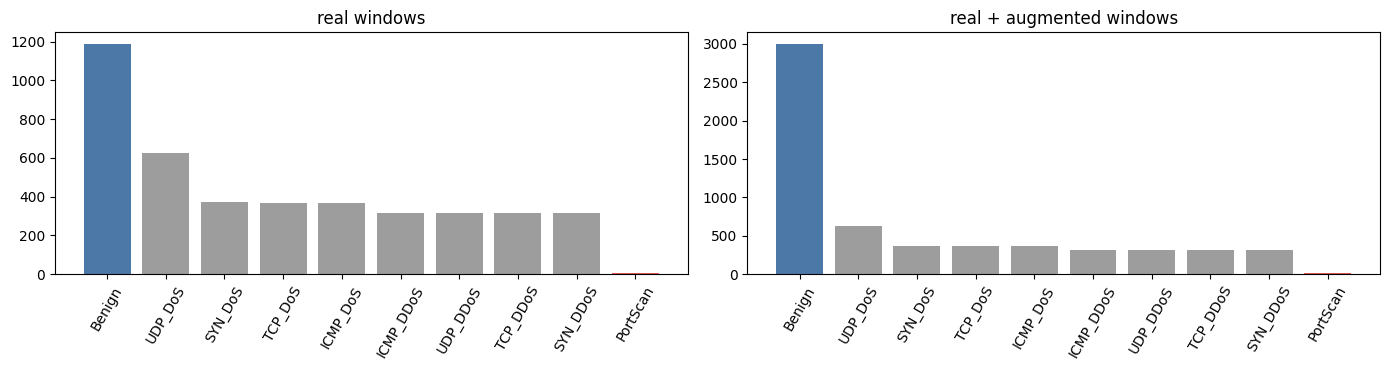

binary ratio attack:benign - real 2.52:1  ->  with augmentation 1.00:1


In [7]:
rows, picked = [], []
real_att = int((CLEAN.is_attack == 1).sum())
for fam in AUG_FAMILIES:
    pool   = AUG_POOL[AUG_POOL.family == fam]
    real_n = int((CLEAN.family == fam).sum())
    target = int(round(BENIGN_TO_ATTACK * real_att)) if fam == "Benign" else FAMILY_FLOOR
    take   = min(max(0, target - real_n), len(pool))
    if take: picked.append(pool.sample(n=take, random_state=RANDOM_STATE))
    rows.append(dict(family=fam, real_windows=real_n, pool_available=len(pool), target=target, added=take, after=real_n + take))
AUG = (pd.concat(picked) if picked else AUG_POOL.iloc[0:0]).assign(is_synthetic=1)
display(pd.DataFrame(rows))
if "PortScan" in AUG_FAMILIES and (CLEAN.family == "PortScan").sum() + (AUG.family == "PortScan").sum() < FAMILY_FLOOR:
    print("NOTE: PortScan stays far below the floor - its captures last only 1-2.4 s, so re-windowing cannot create more independent data.")

before = CLEAN.class_fm.value_counts(); after = before.add(AUG.class_fm.value_counts(), fill_value=0).reindex(before.index)
fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
for a, s, t in [(ax[0], before, "real windows"), (ax[1], after, "real + augmented windows")]:
    a.bar(s.index, s.values, color=["#4c78a8" if i == "Benign" else "#e45756" if i == "PortScan" else "#9d9d9d" for i in s.index]); a.set_title(t); a.tick_params(axis="x", rotation=60)
plt.tight_layout(); plt.savefig(f"{OUT}/network_window_class_counts.png", dpi=110); plt.show()
print(f"binary ratio attack:benign - real {real_att / max(int((CLEAN.family == 'Benign').sum()), 1):.2f}:1  ->  with augmentation "
      f"{real_att / max(int((CLEAN.family == 'Benign').sum()) + int((AUG.family == 'Benign').sum()), 1):.2f}:1")

## 8. Sanity check - does augmentation help? (scenario-held-out)
Train a Random Forest with `class_weight="balanced_subsample"` on (a) real windows only and (b) real + augmented windows, with **whole scenarios held out** per fold. Augmented rows only ever enter *training* folds, from training scenarios. This is a check of the dataset, not a project result; if (b) is not better than (a), prefer class weights and leave the augmented rows out.

In [8]:
if RUN_SANITY:
    from sklearn.ensemble import RandomForestClassifier
    from sklearn.model_selection import GroupKFold
    from sklearn.metrics import f1_score, balanced_accuracy_score, recall_score
    R = CLEAN.copy(); A = AUG.copy()
    gkf = GroupKFold(n_splits=min(5, R.scenario.nunique()))
    res = []
    for name, use_aug in [("real only", False), ("real + augmented", True)]:
        pred = pd.Series(index=R.index, dtype=object)
        for tr, te in gkf.split(R, groups=R.scenario):
            tr_sc = set(R.iloc[tr].scenario)
            Xtr, ytr = R.iloc[tr][FEATURE_COLS], R.iloc[tr].family
            if use_aug and len(A):
                a = A[A.scenario.isin(tr_sc)]; Xtr = pd.concat([Xtr, a[FEATURE_COLS]]); ytr = pd.concat([ytr, a.family])
            rf = RandomForestClassifier(n_estimators=200, max_depth=12, n_jobs=-1, class_weight="balanced_subsample", random_state=RANDOM_STATE).fit(Xtr, ytr)
            pred.iloc[te] = rf.predict(R.iloc[te][FEATURE_COLS])
        y, p = R.family.values, pred.values.astype(str)
        res.append({"training data": name, "family macro-F1": f1_score(y, p, average="macro"),
                    "attack-vs-benign balanced acc": balanced_accuracy_score(R.is_attack, (p != "Benign").astype(int)),
                    "benign recall": recall_score(y == "Benign", p == "Benign"),
                    "PortScan recall": recall_score(y == "PortScan", p == "PortScan") if (y == "PortScan").any() else np.nan})
    display(pd.DataFrame(res))
    print("folds hold out whole scenarios; synthetic rows never reach a test fold.")
else:
    print("sanity check skipped (RUN_SANITY=False)")

,training data,family macro-F1,attack-vs-benign balanced acc,benign recall,PortScan recall
0,real only,0.942,0.996,0.992,0.750
1,real + augmented,0.942,0.997,0.993,0.750


folds hold out whole scenarios; synthetic rows never reach a test fold.


## 9. Shuffle and save
* **`network_features.csv`** - real + augmented windows, **shuffled**. Columns: identifiers and labels (`window_id, scenario, family, mode, class_fm, is_attack`), `is_synthetic`, `aug_phase_s`, time (`window_start_epoch_utc, t_rel_s`), `is_partial`, then the 29 model features. Everything a later notebook needs for grouped splits, alignment and per-class reporting is in the same dataframe; feed only `FEATURE_COLS` to the models.
* **`network_clean.csv`** - real windows only, in **time order**, with the extra alignment and diagnostic columns (UTC and wall-clock start, time-zone label and assumed offset, coverage, `diag_ttl_mean`, `diag_tcp_win_mean`).
* **`network_feature_columns.json`** - the feature list, metadata list and the settings used.

In [9]:
META_COLS = ["window_id", "scenario", "family", "mode", "class_fm", "is_attack", "is_synthetic", "aug_phase_s",
             "window_start_epoch_utc", "t_rel_s", "is_partial"]
real_part = CLEAN.assign(is_synthetic=0, aug_phase_s=0.0)
FEAT = pd.concat([real_part[META_COLS + FEATURE_COLS], AUG[META_COLS + FEATURE_COLS]], ignore_index=True)
FEAT = FEAT.sample(frac=1.0, random_state=RANDOM_STATE).reset_index(drop=True)           # shuffle
CLEAN_OUT = CLEAN.sample(frac=1.0, random_state=RANDOM_STATE).reset_index(drop=True) if SHUFFLE_CLEAN else CLEAN

assert FEAT.window_id.is_unique, "window ids repeat in the features table"
assert FEAT[FEATURE_COLS].notna().all().all()
assert FEAT.loc[FEAT.is_synthetic == 1, "is_attack"].isin([0, 1]).all()

FEAT.to_csv(f"{OUT}/network_features.csv", index=False)
CLEAN_OUT.to_csv(f"{OUT}/network_clean.csv", index=False)
json.dump({"feature_cols": FEATURE_COLS, "meta_cols": META_COLS, "clean_cols": CLEAN_COLS,
           "diag_cols_not_for_models": ["diag_ttl_mean", "diag_tcp_win_mean"],
           "settings": {"window_s": 1, "subbins_per_s": SUBN, "dedup": DEDUP, "field_pick": FIELD_PICK, "tz_offsets_s": TZ_OFFSETS,
                        "min_full_windows": MIN_FULL_WINDOWS, "aug_families": AUG_FAMILIES, "benign_to_attack": BENIGN_TO_ATTACK,
                        "family_floor": FAMILY_FLOOR, "random_state": RANDOM_STATE, "shuffle_clean": SHUFFLE_CLEAN},
           "counts": {"clean_windows": int(len(CLEAN)), "augmented_windows": int(len(AUG)), "features_rows": int(len(FEAT))}},
          open(f"{OUT}/network_feature_columns.json", "w"), indent=2)
SCAN.to_csv(f"{OUT}/network_scan_summary.csv", index=False)

# ---- verify what was written ----
f2, c2 = pd.read_csv(f"{OUT}/network_features.csv"), pd.read_csv(f"{OUT}/network_clean.csv")
print(f"network_features.csv: {f2.shape}   network_clean.csv: {c2.shape}   -> {OUT}")
print("synthetic rows in clean file :", "none" if "is_synthetic" not in c2 else int(c2.is_synthetic.sum()))
print("real rows of features table all present in clean:", set(f2.loc[f2.is_synthetic == 0, "window_id"]) <= set(c2.window_id))
print("features table shuffled     :", not f2.window_start_epoch_utc.is_monotonic_increasing,
      "   clean time-ordered:", c2.window_start_epoch_utc.is_monotonic_increasing)
display(pd.crosstab(f2.class_fm, f2.is_synthetic.map({0: "real", 1: "augmented"}), margins=True))
display(f2.head(5))

network_features.csv: (6007, 40)   network_clean.csv: (4190, 45)   -> /kaggle/working
synthetic rows in clean file : none
real rows of features table all present in clean: True
features table shuffled     : True    clean time-ordered: True


is_synthetic,augmented,real,All
class_fm,,,
Benign,1812,1189,3001
ICMP_DDoS,0,318,318
ICMP_DoS,0,366,366
PortScan,5,8,13
SYN_DDoS,0,314,314
SYN_DoS,0,370,370
TCP_DDoS,0,315,315
TCP_DoS,0,367,367
UDP_DDoS,0,316,316


,window_id,scenario,family,mode,class_fm,is_attack,is_synthetic,aug_phase_s,window_start_epoch_utc,t_rel_s,is_partial,pkts,bytes,mean_len,std_len,min_len,max_len,burst_cv,tcp_frac,udp_frac,icmp_frac,other_frac,gtp_frac,syn_frac,synack_frac,rst_frac,fin_frac,ackonly_frac,tcp_payload_mean,udp_len_mean,n_src,n_dst,n_sport,n_dport,ent_src,ent_dst,ent_dport,top_src_share,top_dst_share,top_dport_share
0,UDP1@6962656100,UDP1,UDP,DoS,UDP_DoS,1,0,0.000,"1,740,664,025.000",72.000,0,"3,468.000","3,780,120.000","1,090.000",22.000,"1,068.000","1,112.000",0.080,0.000,1.000,0.000,0.000,0.500,0.000,0.000,0.000,0.000,0.000,0.000,"1,032.000",3,1,1.000,1.000,1.500,0.000,0.000,0.500,1.000,1.000
1,Benign1@6978536504,Benign1,Benign,Benign,Benign,0,0,0.000,"1,744,634,126.000",43.000,0,33.000,"4,640.000",140.606,41.501,68.000,216.000,1.237,1.000,0.000,0.000,0.000,0.424,0.000,0.000,0.000,0.000,0.242,53.939,0.000,4,4,2.000,2.000,1.163,1.952,0.799,0.758,0.303,0.758
2,Benign6@6978546107,Benign6,Benign,Benign,Benign,0,1,0.750,"1,744,636,526.750",82.750,0,47.000,"7,536.000",160.340,91.008,68.000,428.000,1.327,1.000,0.000,0.000,0.000,0.426,0.000,0.000,0.000,0.000,0.255,73.617,0.000,5,5,3.000,3.000,1.320,2.129,1.260,0.745,0.298,0.638
3,SYN2@6965098228,SYN2,SYN,DoS,SYN_DoS,1,0,0.000,"1,741,274,557.000",44.000,0,"31,280.000","3,128,000.000",100.000,0.000,100.000,100.000,0.045,1.000,0.000,0.000,0.000,1.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,1,1,"12,422.000",1.000,0.000,0.000,0.000,1.000,1.000,1.000
4,Benign4@6978542364,Benign4,Benign,Benign,Benign,0,0,0.000,"1,744,635,591.000",38.000,0,36.000,"4,272.000",118.667,34.795,68.000,188.000,1.732,1.000,0.000,0.000,0.000,0.444,0.000,0.000,0.000,0.000,0.444,31.111,0.000,4,4,2.000,2.000,1.658,1.837,0.991,0.556,0.444,0.556


## 10. How to use these files downstream (read before modelling)
```python
feat = pd.read_csv("network_features.csv"); X_COLS = json.load(open("network_feature_columns.json"))["feature_cols"]
real, syn = feat[feat.is_synthetic == 0], feat[feat.is_synthetic == 1]
# 1) split REAL windows by scenario (GroupKFold / group shuffle on `scenario`)
# 2) add `syn` rows only for scenarios that are in the TRAINING part; never put synthetic rows in validation or test
# 3) report macro-F1, PR-AUC and FPR on real windows only
```
* Paired (multimodal) experiments must use `network_clean.csv` / `is_synthetic == 0` rows: augmented windows are off the whole-second grid and have no radio partner.
* `window_start_epoch_utc` uses the assumed time-zone offsets (`IST = +1 h`). `window_start_wall_epoch` is the timestamp as written in the file; use it if the alignment notebook finds a different offset.
* Benign windows come from only 6 captures, PortScan from 3 very short ones: report per-scenario results and be careful with any claim about those two classes.